# Electricity Load Type Classification

**Objective:** Predict the electricity `Load_Type` (`Light_Load`, `Medium_Load`, or `Maximum_Load`) using electricity usage, power-factor, reactive-power, and time-based features.

This notebook covers:
1. Data loading and cleaning
2. Exploratory data analysis (EDA)
3. Feature engineering
4. Time-based training, validation, and test split
5. Comparison of four classification models
6. Final evaluation on December 2018

**Important:** December 2018 is kept as the final test set. It is not used to select the model.

## 1. Import libraries

Run the next cell to import the libraries used in this notebook. If a library is missing, install it in your environment with `pip install pandas numpy matplotlib seaborn scikit-learn`.

In [3]:
import re
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

Place the CSV file in the same folder as this notebook, or update `FILE_PATH` to the correct path. This notebook expects a `Date_Time` column and a `Load_Type` target column.

In [5]:
FILE_PATH = "load_data.csv"  # Change this to your actual CSV filename

df = pd.read_csv(FILE_PATH)
print("Original dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Original dataset shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load



Column names:
['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']


## 3. Clean column names and data types

Column names are standardized by replacing punctuation and spaces with underscores. `Date_Time` is converted to datetime, and the other feature columns are converted to numeric values where possible.

In [7]:


# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Convert timestamp
df["Date_Time"] = pd.to_datetime(
    df["Date_Time"],
    errors="coerce",
    dayfirst=True
)

# Remove only invalid timestamps or missing target labels
df = df.dropna(subset=["Date_Time", "Load_Type"]).copy()

# Clean target values
df["Load_Type"] = df["Load_Type"].astype(str).str.strip()

# Convert feature columns to numeric
feature_cols = [
    col for col in df.columns
    if col not in ["Date_Time", "Load_Type"]
]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort data chronologically
df = df.sort_values("Date_Time").reset_index(drop=True)

print("Shape after preprocessing:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nRepeated timestamps:", df["Date_Time"].duplicated().sum())

Shape after preprocessing: (35041, 9)

Missing values:


,Missing_Count
Date_Time,0
Usage_kWh,1559
Lagging_Current_Reactive_Power_kVarh,876
Leading_Current_Reactive_Power_kVarh,1156
CO2_tCO2,455
Lagging_Current_Power_Factor,350
Leading_Current_Power_Factor,1471
NSM,455
Load_Type,0



Repeated timestamps: 1


## 4. Check missing values and duplicate timestamps

We check missing values before deciding how to handle them. Missing numerical feature values will be imputed later by each model pipeline using medians calculated from the training data only.

If a timestamp is duplicated, the first row is retained. In the supplied dataset, the duplicate timestamp included a second row with missing `Usage_kWh`; keeping the first row preserves the more complete record.

In [9]:
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing_Count"))

print("Duplicate timestamps before removal:", df["Date_Time"].duplicated().sum())

df = df.sort_values("Date_Time").drop_duplicates(subset=["Date_Time"], keep="first").reset_index(drop=True)

print("Shape after duplicate timestamp removal:", df.shape)
print("Unique timestamps:", df["Date_Time"].nunique())
print("Date range:", df["Date_Time"].min(), "to", df["Date_Time"].max())
print("\nTarget class counts:")
display(df["Load_Type"].value_counts().to_frame("Count"))

Missing values by column:


,Missing_Count
Date_Time,0
Usage_kWh,1559
Lagging_Current_Reactive_Power_kVarh,876
Leading_Current_Reactive_Power_kVarh,1156
CO2_tCO2,455
Lagging_Current_Power_Factor,350
Leading_Current_Power_Factor,1471
NSM,455
Load_Type,0


Duplicate timestamps before removal: 1
Shape after duplicate timestamp removal: (35040, 9)
Unique timestamps: 35040
Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00

Target class counts:


,Count
Load_Type,
Light_Load,18072
Medium_Load,9696
Maximum_Load,7272


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of load types

The target distribution helps us understand whether the classes are balanced or whether some load types occur more often than others.

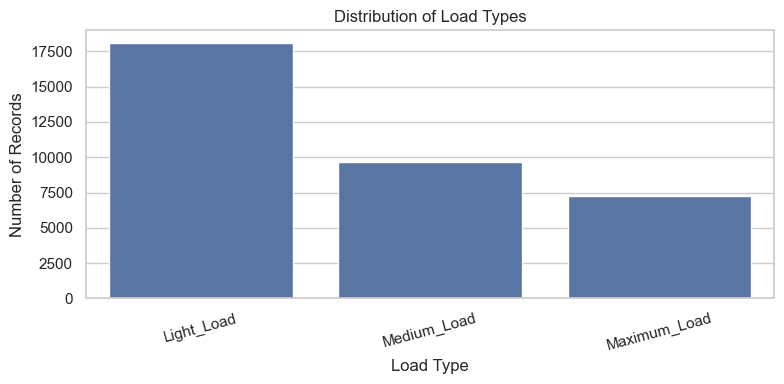

,Percentage
Load_Type,
Light_Load,51.58
Medium_Load,27.67
Maximum_Load,20.75


In [11]:
plt.figure(figsize=(8, 4))
order = df["Load_Type"].value_counts().index
sns.countplot(data=df, x="Load_Type", order=order)
plt.title("Distribution of Load Types")
plt.xlabel("Load Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display((df["Load_Type"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

### 5.2 Missing values

The chart shows how many values are missing in each column. We retain rows with missing numerical features because those values can be imputed inside the model pipeline.

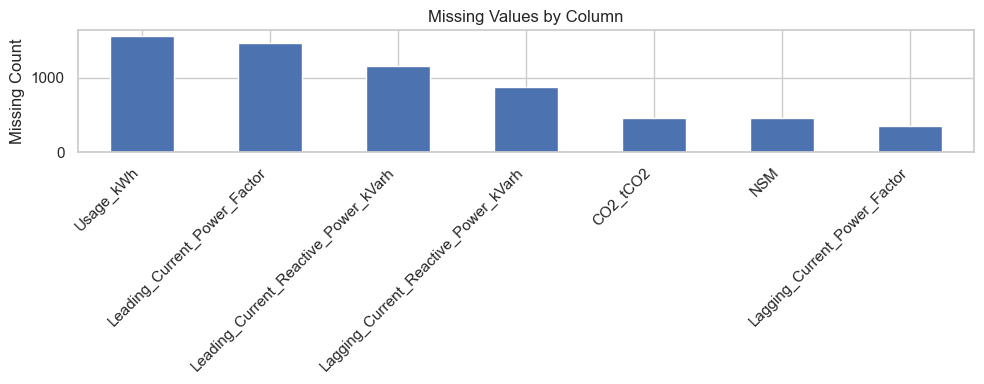

In [13]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]

if len(missing_counts):
    missing_counts.plot(kind="bar", figsize=(10, 4))
    plt.title("Missing Values by Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### 5.3 Average electricity usage by load type

This comparison shows how average `Usage_kWh` differs across the target classes.

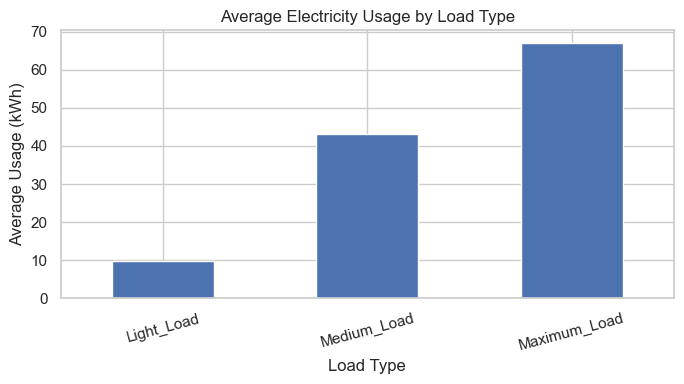

,Mean_Usage_kWh
Load_Type,
Light_Load,9.730547
Medium_Load,43.239931
Maximum_Load,66.945980


In [15]:
if "Usage_kWh" in df.columns:
    usage_by_load = df.groupby("Load_Type")["Usage_kWh"].mean().sort_values()
    usage_by_load.plot(kind="bar", figsize=(7, 4))
    plt.title("Average Electricity Usage by Load Type")
    plt.xlabel("Load Type")
    plt.ylabel("Average Usage (kWh)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    display(usage_by_load.to_frame("Mean_Usage_kWh"))
else:
    print("Usage_kWh column not found; skipping this chart.")

### 5.4 Correlation between numerical features

Correlation helps identify numerical features that move together. The target text labels are excluded from this heatmap.

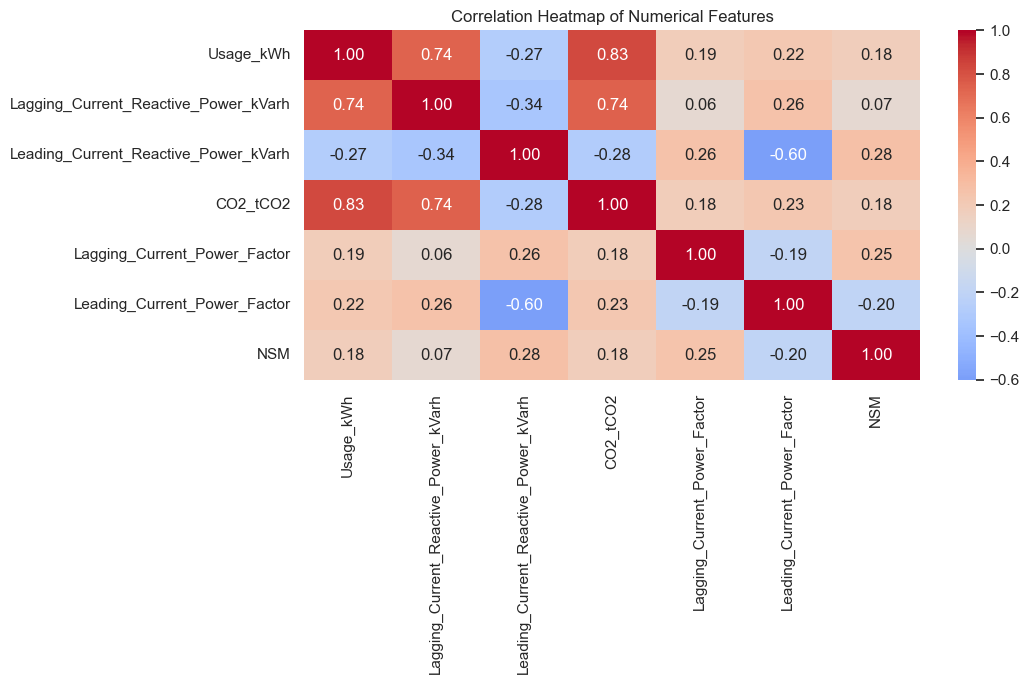

In [17]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(11, 7))
    sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0,fmt=".2f", annot=True)
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")




### 5.5 Number of records per month

This checks the time coverage and supports the time-based split used later.

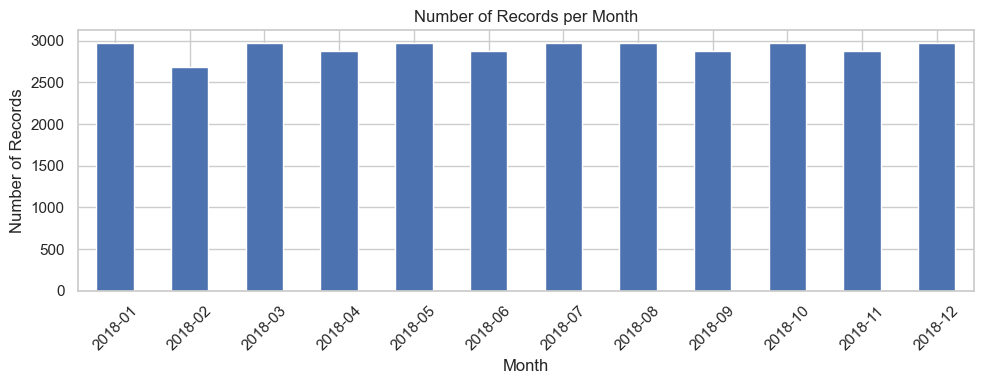

,Record_Count
Date_Time,
2018-01,2976
2018-02,2688
2018-03,2976
2018-04,2880
2018-05,2976
2018-06,2880
2018-07,2976
2018-08,2976
2018-09,2880


In [19]:
monthly_counts = df.set_index("Date_Time").resample("ME").size()
monthly_counts.index = monthly_counts.index.strftime("%Y-%m")

monthly_counts.plot(kind="bar", figsize=(10, 4))
plt.title("Number of Records per Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_counts.to_frame("Record_Count"))

## 6. Feature engineering

We extract hour, day of week, and month from the timestamp. Sine/cosine features represent the cyclical nature of hour and month (for example, hour 23 is close to hour 0).

The original timestamp is not passed directly into the models. `NSM`, if present, is retained as a numeric feature.

In [21]:
df = df.sort_values("Date_Time").reset_index(drop=True)

df["Hour"] = df["Date_Time"].dt.hour
df["DayOfWeek"] = df["Date_Time"].dt.dayofweek
df["Month"] = df["Date_Time"].dt.month

df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)
df["Month_sin"] = np.sin(2 * np.pi * (df["Month"] - 1) / 12)
df["Month_cos"] = np.cos(2 * np.pi * (df["Month"] - 1) / 12)

display(df[["Date_Time", "Hour", "DayOfWeek", "Month", "Hour_sin", "Hour_cos", "Month_sin", "Month_cos", "Load_Type"]].head())

,Date_Time,Hour,DayOfWeek,Month,Hour_sin,Hour_cos,Month_sin,Month_cos,Load_Type
0,2018-01-01 00:00:00,0,0,1,0.000000,1.000000,0.0,1.0,Light_Load
1,2018-01-01 00:15:00,0,0,1,0.000000,1.000000,0.0,1.0,Light_Load
2,2018-01-01 00:30:00,0,0,1,0.000000,1.000000,0.0,1.0,Light_Load
3,2018-01-01 00:45:00,0,0,1,0.000000,1.000000,0.0,1.0,Light_Load
4,2018-01-01 01:00:00,1,0,1,0.258819,0.965926,0.0,1.0,Light_Load


## 7. Split data by time

To respect the chronological order:
- **Training:** January–October 2018
- **Validation:** November 2018 (used to compare models)
- **Testing:** December 2018 (used only for final evaluation)

This avoids randomly mixing future observations into the training data.

In [23]:
train_df = df[df["Date_Time"].dt.month < 11].copy()
val_df = df[df["Date_Time"].dt.month == 11].copy()
test_df = df[df["Date_Time"].dt.month == 12].copy()

print("Training rows (Jan-Oct):", len(train_df))
print("Validation rows (Nov):", len(val_df))
print("Testing rows (Dec):", len(test_df))
print("Total rows:", len(train_df) + len(val_df) + len(test_df))

drop_cols = ["Date_Time", "Load_Type"]
X_train = train_df.drop(columns=drop_cols)
y_train = train_df["Load_Type"]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df["Load_Type"]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df["Load_Type"]

# Ensure validation and test columns exactly match the training feature columns.
X_val = X_val.reindex(columns=X_train.columns)
X_test = X_test.reindex(columns=X_train.columns)

print("\nTraining feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Test feature shape:", X_test.shape)
print("\nTraining target classes:")
print(y_train.value_counts())

Training rows (Jan-Oct): 29184
Validation rows (Nov): 2880
Testing rows (Dec): 2976
Total rows: 35040

Training feature shape: (29184, 14)
Validation feature shape: (2880, 14)
Test feature shape: (2976, 14)

Training target classes:
Load_Type
Light_Load      14960
Medium_Load      8128
Maximum_Load     6096
Name: count, dtype: int64


## 8. Train and compare classification models

We compare Logistic Regression, Random Forest, Extra Trees, and HistGradientBoosting. Median imputation is included in each pipeline so missing values are handled using the training data only. Scaling is included for Logistic Regression.

Models are compared on the November validation set using accuracy, macro precision, macro recall, and macro F1-score. Macro metrics give equal weight to each load type.

In [25]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.1,
            max_leaf_nodes=31,
            random_state=RANDOM_STATE
        ))
    ])
}

results = []
fitted_models = {}
validation_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    fitted_models[name] = model
    validation_predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision_Macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "Recall_Macro": recall_score(y_val, pred, average="macro", zero_division=0),
        "F1_Macro": f1_score(y_val, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1_Macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training Logistic Regression...
Training Random Forest...
Training Extra Trees...
Training HistGradientBoosting...


C:\Users\nidhi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\nidhi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\nidhi\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\nidhi\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\nidhi\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,Random Forest,0.6778,0.5911,0.5917,0.5913
1,HistGradientBoosting,0.6760,0.5890,0.5899,0.5893
2,Extra Trees,0.6660,0.5816,0.5821,0.5818
3,Logistic Regression,0.5962,0.5463,0.5297,0.5354


### 8.1 Compare validation scores

The chart compares the four models on the November validation set. The best model is selected by Macro F1-score rather than accuracy alone.

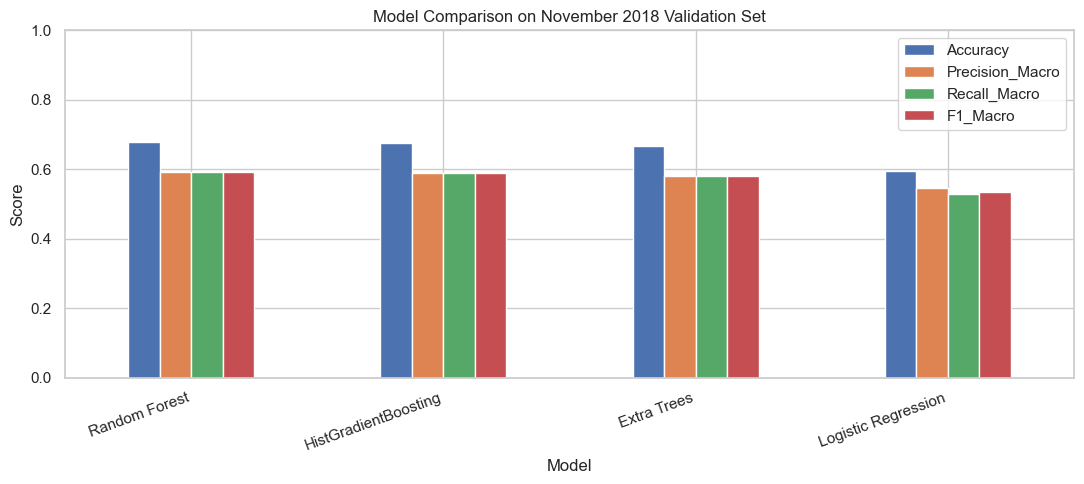

Best model selected using validation Macro F1: Random Forest


In [27]:
results_plot = results_df.set_index("Model")[["Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro"]]
results_plot.plot(kind="bar", figsize=(11, 5))
plt.title("Model Comparison on November 2018 Validation Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Best model selected using validation Macro F1:", best_model_name)

### 8.2 Detailed validation report

This report helps check performance for each class before the final test evaluation.

              precision    recall  f1-score   support

  Light_Load       0.96      0.97      0.97      1368
 Medium_Load       0.48      0.47      0.47       864
Maximum_Load       0.33      0.33      0.33       648

    accuracy                           0.68      2880
   macro avg       0.59      0.59      0.59      2880
weighted avg       0.68      0.68      0.68      2880



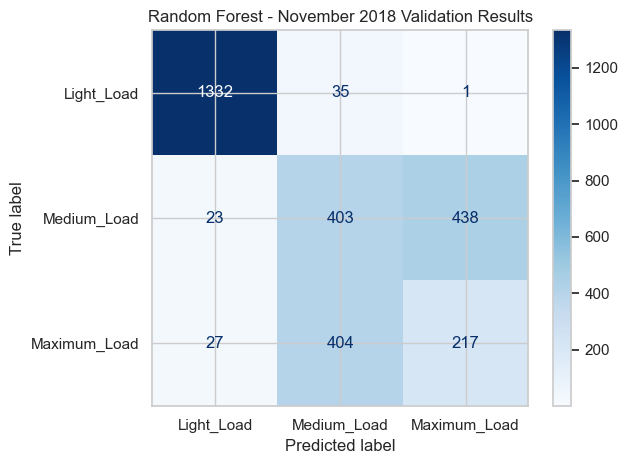

In [29]:
class_labels = ["Light_Load", "Medium_Load", "Maximum_Load"]

val_pred = validation_predictions[best_model_name]
print(classification_report(
    y_val,
    val_pred,
    labels=class_labels,
    zero_division=0
))

val_cm = confusion_matrix(y_val, val_pred, labels=class_labels)
ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")
plt.title(f"{best_model_name} - November 2018 Validation Results")
plt.tight_layout()
plt.show()

## 9. Final evaluation on December 2018

The model selected from the November validation results is evaluated on December 2018. The December test set is not used for model selection.

Final model: Random Forest
Test Accuracy:  0.7440
Test Precision: 0.6116
Test Recall:    0.6122
Test Macro F1:  0.6119

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.96      0.95      0.96      1744
 Medium_Load       0.49      0.49      0.49       704
Maximum_Load       0.39      0.40      0.39       528

    accuracy                           0.74      2976
   macro avg       0.61      0.61      0.61      2976
weighted avg       0.75      0.74      0.74      2976



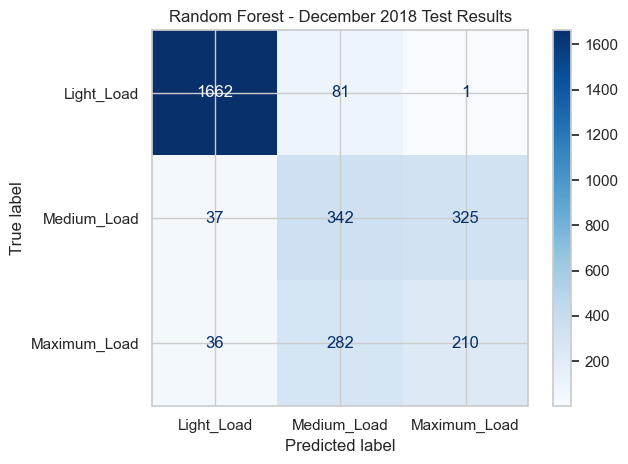

In [31]:
test_predictions = best_model.predict(X_test)

test_metrics = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision_Macro": precision_score(y_test, test_predictions, average="macro", zero_division=0),
    "Recall_Macro": recall_score(y_test, test_predictions, average="macro", zero_division=0),
    "F1_Macro": f1_score(y_test, test_predictions, average="macro", zero_division=0)
}

print("Final model:", best_model_name)
print(f"Test Accuracy:  {test_metrics['Accuracy']:.4f}")
print(f"Test Precision: {test_metrics['Precision_Macro']:.4f}")
print(f"Test Recall:    {test_metrics['Recall_Macro']:.4f}")
print(f"Test Macro F1:  {test_metrics['F1_Macro']:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=class_labels,
    zero_division=0
))

test_cm = confusion_matrix(y_test, test_predictions, labels=class_labels)
ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=class_labels
).plot(cmap="Blues", values_format="d")
plt.title(f"{best_model_name} - December 2018 Test Results")
plt.tight_layout()
plt.show()

## 10. Conclusion

The model comparison selects the classifier with the highest Macro F1-score on the November validation set. The final December metrics above provide the estimate of how well the selected model generalizes to later data.

Review the class-wise precision, recall, and F1-score as well as accuracy. If performance is much stronger for one class than the others, consider further feature engineering or hyperparameter tuning. Do not tune based on the December test results; use a validation set for any further model changes.